# Seminar 1 · Part 2: The spam filter

We build a **spam filter from scratch** with nothing but counting and Bayes' formula.

**Plan of this notebook**

1. Load the data
2. Look at the data (EDA)
3. Build the classifier from scratch
4. Train it
5. Use it
6. Evaluate it
7. Can you fool it?

In [2]:
import re                          # regular expressions: to cut a message into words
from collections import Counter    # a dictionary that counts things
import math

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 0                           # fixed random seed: everyone gets the same split and the same numbers
HAM_COLOR, SPAM_COLOR = "#eb6834", "#2a78d6"   # the slide colours: spam = the positive class

## 1. Load the data

**The SMS Spam Collection** (Almeida and Gómez Hidalgo, 2011), from the UCI Machine Learning Repository, licence CC BY 4.0.

One text file, one message per line: the **gold label** (`ham` or `spam`), a tab, then the message.

In [3]:
rows = []
with open("../data/SMSSpamCollection", encoding="utf-8") as f:
    for line in f:
        label, text = line.rstrip("\n").split("\t", 1)   # split at the first tab only
        rows.append((label, text))

data = pd.DataFrame(rows, columns=["label", "text"])
print("Messages:", len(data))
data.head()

Messages: 5574


,label,text
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


**Repeated messages.** Some messages appear more than once. If the same message lands in both the training set and the test set, the test becomes too easy and the score looks better than it is. So we keep only the first copy of each message.

In [4]:
before = len(data)
data = data.drop_duplicates(subset="text").reset_index(drop=True)
print("Removed repeats:", before - len(data))
print("Messages left:  ", len(data))

Removed repeats: 403
Messages left:   5171


## 2. Look at the data (EDA)

### How many ham and how many spam?

label
ham     4518
spam     653
Name: count, dtype: int64

Spam is 12.6% of the messages.


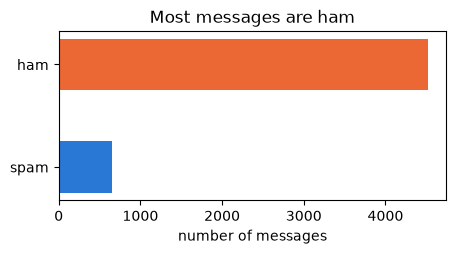

In [5]:
counts = data["label"].value_counts()
print(counts)
print()
print(f"Spam is {counts['spam'] / len(data):.1%} of the messages.")

plt.figure(figsize=(5, 2.2))
plt.barh(["spam", "ham"], [counts["spam"], counts["ham"]], color=[SPAM_COLOR, HAM_COLOR], height=0.5)
plt.xlabel("number of messages")
plt.title("Most messages are ham")
plt.show()

**Trap question.** A "filter" that answers **ham** for every message, without reading it. What is its accuracy?

In [6]:
accuracy_always_ham = counts["ham"] / len(data)
print(f"Accuracy of 'always ham': {accuracy_always_ham:.1%}")
print("...and it catches 0 spam messages. Accuracy alone can fool us.")

Accuracy of 'always ham': 87.4%
...and it catches 0 spam messages. Accuracy alone can fool us.


### Some messages

In [7]:
pd.set_option("display.max_colwidth", 120)
print("SPAM:")
for t in data[data["label"] == "spam"]["text"].head(4):
    print("  -", t)
print("\nHAM:")
for t in data[data["label"] == "ham"]["text"].head(4):
    print("  -", t)

SPAM:
  - Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply 08452810075over18's
  - FreeMsg Hey there darling it's been 3 week's now and no word back! I'd like some fun you up for it still? Tb ok! XxX std chgs to send, £1.50 to rcv
  - WINNER!! As a valued network customer you have been selected to receivea £900 prize reward! To claim call 09061701461. Claim code KL341. Valid 12 hours only.
  - Had your mobile 11 months or more? U R entitled to Update to the latest colour mobiles with camera for Free! Call The Mobile Update Co FREE on 08002986030

HAM:
  - Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...
  - Ok lar... Joking wif u oni...
  - U dun say so early hor... U c already then say...
  - Nah I don't think he goes to usf, he lives around here though


### Words

A **word** (in our code) is a run of letters and digits, after we turn the message into lower case.

In [8]:
def words(text):
    # "Free entry in 2 a wkly comp!" -> ['free', 'entry', 'in', '2', 'a', 'wkly', 'comp']
    return re.findall(r"[a-z0-9]+", text.lower())

print(words("Free entry in 2 a wkly comp to win FA Cup final tkts!"))

['free', 'entry', 'in', '2', 'a', 'wkly', 'comp', 'to', 'win', 'fa', 'cup', 'final', 'tkts']


### How long are the messages?

       mean  median
label              
ham    14.7    11.0
spam   25.3    27.0


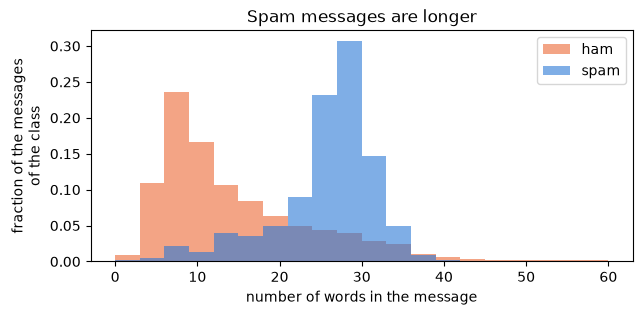

In [9]:
data["n_words"] = data["text"].apply(lambda t: len(words(t)))
print(data.groupby("label")["n_words"].agg(["mean", "median"]).round(1))

bins = np.arange(0, 61, 3)                  # bins of 3 words; the few messages longer than 60 words are not drawn
plt.figure(figsize=(7, 3))
for label, color in [("ham", HAM_COLOR), ("spam", SPAM_COLOR)]:
    lengths = data[data["label"] == label]["n_words"]
    weights = np.ones(len(lengths)) / len(lengths)   # each message counts 1 / (number of messages of its class)
    plt.hist(lengths, bins=bins, weights=weights, color=color, alpha=0.6, label=label)
plt.xlabel("number of words in the message")
plt.ylabel("fraction of the messages\nof the class")
plt.legend()
plt.title("Spam messages are longer")
plt.show()

**Keep this in mind:** our model will assume that the length $n$ says nothing about the class. The data says otherwise. The model is *naive*.


## 3. Build the classifier from scratch

### The model, in one line

A message is a **bag of words**: its word counts $x = (x_w)_{w \in V}$. Under the naive Bayes assumption, the predicted class is

$$\hat{c} = \operatorname*{argmax}_{c} \Big[\log \hat{P}(\eta = c) + \sum_{w \in V} x_w \log \hat{p}_c(w)\Big]$$

with the estimates (Laplace smoothing)

$$\hat{P}(\eta = c) = \frac{m_c}{m}, \qquad \hat{p}_c(w) = \frac{\text{count}(w, c) + 1}{\sum_{w' \in V} \text{count}(w', c) + |V|}.$$

The two functions below follow the pseudocode of Jurafsky & Martin, Appendix B, Fig. B.2.

In [11]:
def train_naive_bayes(texts, labels):
    '''Training = counting. Returns the vocabulary V, log P^(eta = c) and log p^_c(w).'''
    m = len(texts)                                   # number of training messages
    classes = sorted(set(labels))                    # ['ham', 'spam']

    # count(w, c): how often word w appears in all training messages of class c
    count = {c: Counter() for c in classes}
    for text, c in zip(texts, labels):
        count[c].update(words(text))

    V = set()                                        # the vocabulary: words of BOTH classes
    for c in classes:
        V.update(count[c])

    log_prior, log_p = {}, {}
    for c in classes:
        m_c = sum(1 for label in labels if label == c)
        log_prior[c] = math.log(m_c / m)                                  # log P^(eta = c)

        total = sum(count[c].values())                                    # sum over w' of count(w', c)
        log_p[c] = {w: math.log((count[c][w] + 1) / (total + len(V)))     # Laplace smoothing
                    for w in V}
    return V, log_prior, log_p


def log_scores(text, V, log_prior, log_p):
    '''For each class c: log P^(eta = c) + sum_w x_w log p^_c(w).'''
    x = Counter(w for w in words(text) if w in V)    # the counts x_w; unknown words are removed
    return {c: log_prior[c] + sum(x_w * log_p[c][w] for w, x_w in x.items())
            for c in log_prior}


def predict(text, V, log_prior, log_p):
    '''The predicted class c^: the class with the largest score (argmax).'''
    s = log_scores(text, V, log_prior, log_p)
    return max(s, key=s.get)


def posterior_spam(text, V, log_prior, log_p):
    '''P^(eta = spam | xi = x).
    Bayes' formula with two classes: P(spam | x) = a_spam / (a_spam + a_ham), where a_c = exp(score_c).
    Dividing top and bottom by a_spam gives 1 / (1 + exp(score_ham - score_spam)), which never underflows.'''
    s = log_scores(text, V, log_prior, log_p)
    return 1 / (1 + math.exp(s["ham"] - s["spam"]))

### Check the code on the 12 toy messages from the slides

On the slides we computed by hand, **with** Laplace smoothing: "free win money meeting" is spam with $\hat{P}(\eta = \text{spam} \mid \xi = x) \approx 0.74$. Our code should give the same number.

For "free money" the slides found 0.88, but that was **without** smoothing. With smoothing (as in our code) the answer changes a little: $\approx 0.76$.

In [12]:
toy_texts = ["lunch meeting", "meeting lunch", "free lunch", "lunch money",
             "meeting", "meeting money", "lunch", "meeting lunch meeting",       # 8 ham
             "free money", "win money", "win free free", "free win money money"]  # 4 spam
toy_labels = ["ham"] * 8 + ["spam"] * 4

toy_model = train_naive_bayes(toy_texts, toy_labels)
for t in ["free money", "free win money meeting"]:
    print(f"{t!r:28} -> {predict(t, *toy_model):5}  P^(spam | x) = {posterior_spam(t, *toy_model):.2f}")

'free money'                 -> spam   P^(spam | x) = 0.76
'free win money meeting'     -> spam   P^(spam | x) = 0.74


### Why logarithms? Underflow

A product of many small numbers becomes exactly `0.0` in the computer. Let's multiply the probabilities $\hat{p}_c(w)$ of the words of a long message.

In [13]:
long_message = " ".join(["lunch", "meeting", "free", "money"] * 150)   # 600 words
x = Counter(words(long_message))

product = 1.0
log_sum = 0.0
for w, x_w in x.items():
    product *= math.exp(toy_model[2]["ham"][w]) ** x_w    # multiply the probabilities
    log_sum += x_w * toy_model[2]["ham"][w]               # add the logarithms

print("product of probabilities:", product)    # 0.0: underflow
print("sum of logarithms:       ", log_sum)    # a normal number

product of probabilities: 0.0
sum of logarithms:        -944.9023990315924


## 4. Train it

First we split the messages: **80% training set**, **20% test set**. The test set stays hidden until step 6.

In [14]:
rng = np.random.default_rng(SEED)
order = rng.permutation(len(data))           # the messages in a random order
n_train = int(0.8 * len(data))

train = data.iloc[order[:n_train]].reset_index(drop=True)
test = data.iloc[order[n_train:]].reset_index(drop=True)
print("Training set:", len(train), "messages")
print("Test set:    ", len(test), "messages")

Training set: 4136 messages
Test set:     1035 messages


In [15]:
model = train_naive_bayes(list(train["text"]), list(train["label"]))
V, log_prior, log_p = model

print("Vocabulary size |V|:", len(V))
print("P^(eta = ham) =", round(math.exp(log_prior["ham"]), 3), "  P^(eta = spam) =", round(math.exp(log_prior["spam"]), 3))

Vocabulary size |V|: 7732
P^(eta = ham) = 0.873   P^(eta = spam) = 0.127


### What did it learn?

The most "spammy" words: the largest $\log \hat{p}_{\text{spam}}(w) - \log \hat{p}_{\text{ham}}(w)$. We only look at words that appear at least 10 times in the training set, so that rare words don't fill the list.

In [17]:
total_count = Counter()
for t in train["text"]:
    total_count.update(words(t))

common = sorted(w for w in V if total_count[w] >= 10)   # sorted: ties always come out in the same order
spamminess = {w: log_p["spam"][w] - log_p["ham"][w] for w in common}
ranked = sorted(common, key=spamminess.get)

print("Most spammy:", ranked[-12:][::-1])
print("Most hammy: ", ranked[:12])

Most spammy: ['claim', 'prize', '150p', 'uk', 'tone', 'guaranteed', '18', 'www', '500', 'cs', '100', 'awarded']
Most hammy:  ['gt', 'lt', 'he', 'home', 'lor', 'she', 'da', 'later', 'wat', 'ask', 'doing', 'lol']


**Surprise:** the top hammy words `gt` and `lt` are not real words. They come from the text `&lt;#&gt;`, which appears only in ham messages of this dataset. The model learns any pattern in the data, even a strange one.

## 5. Use it

Write your own messages and try them.

In [18]:
my_messages = [
    "Congratulations! You have won a FREE prize. Call now to claim",
    "are we still meeting for lunch tomorrow?",
    "URGENT your mobile number has been selected, reply WIN",
    "sorry i will be late, see you at home",
]
for t in my_messages:
    print(f"{predict(t, *model):5}  P^(spam | x) = {posterior_spam(t, *model):.3f}   {t}")

spam   P^(spam | x) = 1.000   Congratulations! You have won a FREE prize. Call now to claim
ham    P^(spam | x) = 0.000   are we still meeting for lunch tomorrow?
spam   P^(spam | x) = 1.000   URGENT your mobile number has been selected, reply WIN
ham    P^(spam | x) = 0.000   sorry i will be late, see you at home


## 6. Evaluate it

Now the test set. The **confusion matrix** counts the test messages by gold label and by predicted class. Spam is the positive class.

In [19]:
def confusion(gold, predicted, positive="spam"):
    '''The four counts TP, FP, FN, TN.'''
    TP = sum(g == positive and p == positive for g, p in zip(gold, predicted))
    FP = sum(g != positive and p == positive for g, p in zip(gold, predicted))
    FN = sum(g == positive and p != positive for g, p in zip(gold, predicted))
    TN = sum(g != positive and p != positive for g, p in zip(gold, predicted))
    return TP, FP, FN, TN


def scores(TP, FP, FN, TN):
    precision = TP / (TP + FP) if TP + FP > 0 else float("nan")   # nan: no message was called spam
    recall = TP / (TP + FN)
    accuracy = (TP + TN) / (TP + FP + FN + TN)
    return precision, recall, accuracy


predicted = [predict(t, *model) for t in test["text"]]
TP, FP, FN, TN = confusion(test["label"], predicted)

print(pd.DataFrame([[TP, FP], [FN, TN]],
                   index=["predicted spam", "predicted ham"],
                   columns=["gold spam", "gold ham"]))
precision, recall, accuracy = scores(TP, FP, FN, TN)
print(f"\nprecision = {precision:.3f}   recall = {recall:.3f}   accuracy = {accuracy:.3f}")

                gold spam  gold ham
predicted spam        114         2
predicted ham          12       907

precision = 0.983   recall = 0.905   accuracy = 0.986


**Compare with "always ham"** on the same test set:

In [20]:
always_ham = ["ham"] * len(test)
p, r, a = scores(*confusion(test["label"], always_ham))
print(f"'always ham':  precision = {p}   recall = {r:.3f}   accuracy = {a:.3f}")

'always ham':  precision = nan   recall = 0.000   accuracy = 0.878


### The mistakes

In [21]:
test["predicted"] = predicted
print("Spam that got through (false negatives):")
for t in test[(test["label"] == "spam") & (test["predicted"] == "ham")]["text"].head(5):
    print("  -", t)
print("\nHam sent to the spam folder (false positives):")
for t in test[(test["label"] == "ham") & (test["predicted"] == "spam")]["text"].head(5):
    print("  -", t)

Spam that got through (false negatives):
  - Hi this is Amy, we will be sending you a free phone number in a couple of days, which will give you an access to all the adult parties...
  - Ever thought about living a good life with a perfect partner? Just txt back NAME and AGE to join the mobile community. (100p/SMS)
  - Guess who am I?This is the first time I created a web page WWW.ASJESUS.COM read all I wrote. I'm waiting for your opinions. I want to be your friend 1/1
  - Hi ya babe x u 4goten bout me?' scammers getting smart..Though this is a regular vodafone no, if you respond you get further prem rate msg/subscription. Other nos used also. Beware!
  - Would you like to see my XXX pics they are so hot they were nearly banned in the uk!

Ham sent to the spam folder (false positives):
  - Anytime...
  - Unlimited texts. Limited minutes.


### 10-fold cross-validation (on the training set)

One test set gives one number. Is it luck? Cross-validation repeats the experiment $k = 10$ times: split the training set into 10 folds, train on 9, test on the 10th, and average.

In [22]:
k = 10
folds = np.array_split(np.arange(len(train)), k)   # the training set is already in random order
results = []
for fold in folds:
    inside = np.setdiff1d(np.arange(len(train)), fold)          # the other k - 1 folds
    fold_model = train_naive_bayes(list(train["text"].iloc[inside]), list(train["label"].iloc[inside]))
    fold_predicted = [predict(t, *fold_model) for t in train["text"].iloc[fold]]
    results.append(scores(*confusion(train["label"].iloc[fold], fold_predicted)))

results = pd.DataFrame(results, columns=["precision", "recall", "accuracy"])
print(results.round(3))
print("\nmean:")
print(results.mean().round(3))

   precision  recall  accuracy
0      0.982   0.900     0.983
1      0.978   0.898     0.986
2      0.959   0.959     0.990
3      0.949   0.925     0.988
4      0.944   0.864     0.973
5      0.966   0.905     0.981
6      0.980   0.907     0.985
7      0.982   0.902     0.983
8      1.000   0.979     0.998
9      0.977   0.955     0.993

mean:
precision    0.972
recall       0.919
accuracy     0.986
dtype: float64


## 7. Can you fool the model?

The model only counts words. So a spammer can add **hammy** words to a spam message. Let's take a spam message from the test set and add ordinary words, one at a time.

In [23]:
spam_message = test[(test["label"] == "spam") & (test["predicted"] == "spam")]["text"].iloc[0]
print("Original:", spam_message)
print(f"P^(spam | x) = {posterior_spam(spam_message, *model):.4f}\n")

hammy = [w for w in ranked if w not in ("gt", "lt")][:8]   # the 8 most hammy real words from step 4
message = spam_message
for w in hammy:
    message = message + " " + w
    print(f"+ {w:8}  P^(spam | x) = {posterior_spam(message, *model):.4f}  -> {predict(message, *model)}")

Original: RECPT 1/3. You have ordered a Ringtone. Your order is being processed...
P^(spam | x) = 0.9983

+ he        P^(spam | x) = 0.9073  -> spam
+ home      P^(spam | x) = 0.1848  -> ham
+ lor       P^(spam | x) = 0.0052  -> ham
+ she       P^(spam | x) = 0.0001  -> ham
+ da        P^(spam | x) = 0.0000  -> ham
+ later     P^(spam | x) = 0.0000  -> ham
+ wat       P^(spam | x) = 0.0000  -> ham
+ ask       P^(spam | x) = 0.0000  -> ham


**Your turn.** Write a spam message that the model calls ham, or a normal message that it calls spam. Why does it work? Which assumption of the model are you using?

In [24]:
my_attack = "WIN a FREE holiday! Text YES to 80082"
print(f"{predict(my_attack, *model):5}  P^(spam | x) = {posterior_spam(my_attack, *model):.3f}")

spam   P^(spam | x) = 1.000


## Summary

- Spam filtering = **Bayes' formula** + the **naive Bayes assumption** + **counting**.
- Training is counting; Laplace smoothing fixes the zero counts; logarithms fix underflow.
- Measure with **precision and recall**, not only accuracy.
- The model ignores word order and message length. It is naive, and still very good.

**Read more:** Jurafsky & Martin, *Speech and Language Processing*, Appendix B (https://web.stanford.edu/~jurafsky/slp3/B.pdf).